**TRABAJO FINAL MARTINEZ**

Nombre del Dataset: Cardiovascular Disease Dataset (cardio_train.csv). Fuente pública de referencia: [Cardiovascular Disease dataset, Svetlana Ulianova](https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset). Este conjunto de datos es altamente relevante para el análisis de salud pública y epidemiología clínica. Contiene variables cuantitativas continuas y discretas (edad, peso, altura, presión arterial sistólica y diastólica) así como variables cualitativas/categóricas (colesterol, glucosa, tabaquismo, consumo de alcohol, actividad física y diagnóstico de enfermedad cardiovascular), permitiendo cruzar factores de riesgo múltiples para obtener insights trazables.

Pregunta inicial: ¿Qué relaciones se observan entre los factores clínicos (presión arterial, colesterol y glucosa), los hábitos de vida (tabaquismo, consumo de alcohol y actividad física) y la presencia de enfermedades cardiovasculares en la población estudiada?

Objetivo del trabajo: Analizar los datos para identificar asociaciones entre las variables estudiadas y el diagnóstico cardiovascular, mediante técnicas de limpieza, estadística descriptiva y visualización.
Herramientas utilizadas: Se utiliza Google Colab con Python y las bibliotecas Pandas, Matplotlib y Seaborn para preparar, analizar y visualizar los datos. Posteriormente, se utilizará Power BI para desarrollar un dashboard interactivo.

### 1. Información General del Dataset



In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [73]:
data = pd.read_csv("/content/cardio_train.csv",sep=";")

In [74]:
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


Se cargó el archivo cardio_train.csv especificando el separador de punto y coma (;), obteniendo una matriz inicial de 70,000 registros y 13 variables.

In [75]:
print(f"Dimensiones del dataset: {data.shape[0]} filas y {data.shape[1]} columnas.\n")
print("Información general:")
data.info()

Dimensiones del dataset: 70000 filas y 13 columnas.

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [76]:
data.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


## 2. Limpieza y preparación de datos

Se realizó una auditoría inicial del dataset para identificar valores nulos, registros duplicados e inconsistencias en las variables.
Posteriormente, se aplicaron criterios de depuración sobre la presión arterial sistólica y diastólica, la altura y el peso, eliminando 1.456 registros (2,08%) y conservando 68.544 observaciones. Además, se transformó la edad de días a años, se convirtió la altura de centímetros a metros y se calculó el índice de masa corporal (IMC).
Finalmente, se verificó la consistencia de los datos mediante controles de valores nulos, duplicados y categorías válidas, preparando el dataset para su posterior análisis estadístico y visualización.

La columna original age expresa la edad en días. Se creó la variable age_years dividiendo por 365,25 y redondeando a un decimal, para obtener una edad aproximada en años.

En bases de datos médicas masivas, suelen aparecer errores de carga evidentes (por ejemplo, presiones arteriales negativas, sistólicas de más de 300 mmHg o alturas de 50 cm en adultos). Se establecieron rangos de validación para identificar y excluir registros con valores extremos o inconsistentes de presión arterial, altura y peso. Esta depuración permitió mejorar la consistencia de los datos, aunque podría modificar la composición de la muestra analizada.

In [77]:
data_original = pd.read_csv(
    "/content/cardio_train.csv",
    sep=";"
)

print("=== AUDITORÍA INICIAL ===")
print("Registros:", len(data_original))
print("Columnas:", len(data_original.columns))

print("\nValores nulos por columna:")
print(data_original.isnull().sum())

print("\nFilas completamente duplicadas:")
print(data_original.duplicated().sum())

print("\nIdentificadores ID repetidos:")
print(data_original['id'].duplicated().sum())

print("\nTipos de datos:")
print(data_original.dtypes)


=== AUDITORÍA INICIAL ===
Registros: 70000
Columnas: 13

Valores nulos por columna:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Filas completamente duplicadas:
0

Identificadores ID repetidos:
0

Tipos de datos:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object


In [78]:
data_clean = data_original.drop_duplicates().copy()

rango_sistolica = (80, 220)
rango_diastolica = (50, 120)
rango_altura_cm = (120, 220)
rango_peso = (30, 200)

condiciones = (
    data_clean['ap_hi'].between(*rango_sistolica)
    & data_clean['ap_lo'].between(*rango_diastolica)
    & (data_clean['ap_hi'] > data_clean['ap_lo'])
    & data_clean['height'].between(*rango_altura_cm)
    & data_clean['weight'].between(*rango_peso)
)

data_clean = data_clean.loc[condiciones].copy()

print("=== RESULTADOS DE LIMPIEZA ===")
print("Registros originales:", len(data_original))
print("Registros limpios:", len(data_clean))
print("Registros eliminados:",
      len(data_original) - len(data_clean))


=== RESULTADOS DE LIMPIEZA ===
Registros originales: 70000
Registros limpios: 68544
Registros eliminados: 1456


In [79]:
criterios = {
    'Presión sistólica fuera de rango':
        ~data_original['ap_hi'].between(80, 220),

    'Presión diastólica fuera de rango':
        ~data_original['ap_lo'].between(50, 120),

    'Presión sistólica menor o igual a diastólica':
        data_original['ap_hi'] <= data_original['ap_lo'],

    'Altura fuera de rango':
        ~data_original['height'].between(120, 220),

    'Peso fuera de rango':
        ~data_original['weight'].between(30, 200)
}

resultados_auditoria = pd.DataFrame({
    'Criterio': list(criterios.keys()),
    'Registros afectados': [
        condicion.sum() for condicion in criterios.values()
    ]
})

resultados_auditoria['Porcentaje (%)'] = (
    resultados_auditoria['Registros afectados']
    / len(data_original) * 100
)

print("=== MOTIVOS DE EXCLUSIÓN ===")
display(resultados_auditoria.round(2))

registros_excluidos = data_original.loc[
    ~data_original.index.isin(data_clean.index)
].copy()

comparacion_limpieza = pd.DataFrame({
    'Grupo': ['Original', 'Conservados', 'Excluidos'],
    'Registros': [
        len(data_original),
        len(data_clean),
        len(registros_excluidos)
    ],
    'Prevalencia cardiovascular (%)': [
        data_original['cardio'].mean() * 100,
        data_clean['cardio'].mean() * 100,
        registros_excluidos['cardio'].mean() * 100
    ]
})

print("=== COMPARACIÓN ANTES Y DESPUÉS DE LA LIMPIEZA ===")
display(comparacion_limpieza.round(2))

=== MOTIVOS DE EXCLUSIÓN ===


,Criterio,Registros afectados,Porcentaje (%)
0,Presión sistólica fuera de rango,255,0.36
1,Presión diastólica fuera de rango,1136,1.62
2,Presión sistólica menor o igual a diastólica,1236,1.77
3,Altura fuera de rango,53,0.08
4,Peso fuera de rango,7,0.01


=== COMPARACIÓN ANTES Y DESPUÉS DE LA LIMPIEZA ===


,Grupo,Registros,Prevalencia cardiovascular (%)
0,Original,70000,49.97
1,Conservados,68544,49.44
2,Excluidos,1456,74.79


Se excluyeron 1.456 registros (2,08%), principalmente por inconsistencias en la presión arterial. La prevalencia cardiovascular disminuyó del 49,97% al 49,44% después de la limpieza. Los registros excluidos presentaban una prevalencia del 74,79%, lo que indica que la depuración podría introducir un sesgo en la muestra analizada.

In [80]:
data_clean['age_years'] = (
    data_clean['age'] / 365.25
).round(1)

data_clean['height_m'] = (
    data_original.loc[data_clean.index, 'height'] / 100
)

data_clean['imc'] = (
    data_clean['weight'] /
    (data_clean['height_m'] ** 2)
)

print("=== VARIABLES TRANSFORMADAS ===")

display(
    data_clean[
        ['age_years', 'height_m', 'weight', 'imc']
    ].head()
)

=== VARIABLES TRANSFORMADAS ===


,age_years,height_m,weight,imc
0,50.4,1.68,62.0,21.967120
1,55.4,1.56,85.0,34.927679
2,51.6,1.65,64.0,23.507805
3,48.2,1.69,82.0,28.710479
4,47.8,1.56,56.0,23.011177


Se convirtió la edad de días a años aproximados y la altura de centímetros a metros. Además, se calculó el índice de masa corporal (IMC) a partir del peso y la altura.

In [81]:
categoricas = [
    'gender', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active', 'cardio'
]

print("=== CONTROL DE CATEGORÍAS ===")

for columna in categoricas:
    print(f"\nVariable: {columna}")
    print(data_clean[columna].value_counts().sort_index())

=== CONTROL DE CATEGORÍAS ===

Variable: gender
gender
1    44652
2    23892
Name: count, dtype: int64

Variable: cholesterol
cholesterol
1    51410
2     9281
3     7853
Name: count, dtype: int64

Variable: gluc
gluc
1    58282
2     5054
3     5208
Name: count, dtype: int64

Variable: smoke
smoke
0    62520
1     6024
Name: count, dtype: int64

Variable: alco
alco
0    64891
1     3653
Name: count, dtype: int64

Variable: active
active
0    13484
1    55060
Name: count, dtype: int64

Variable: cardio
cardio
0    34654
1    33890
Name: count, dtype: int64


In [82]:
print("=== VALIDACIÓN FINAL ===")

print("Registros limpios:", len(data_clean))
print("Columnas:", len(data_clean.columns))
print("Valores nulos:", data_clean.isnull().sum().sum())
print("Filas duplicadas:", data_clean.duplicated().sum())
print("ID repetidos:", data_clean['id'].duplicated().sum())

categorias_validas = {
    'gender': [1, 2],
    'cholesterol': [1, 2, 3],
    'gluc': [1, 2, 3],
    'smoke': [0, 1],
    'alco': [0, 1],
    'active': [0, 1],
    'cardio': [0, 1]
}

for columna, valores in categorias_validas.items():
    invalidos = (~data_clean[columna].isin(valores)).sum()
    print(f"{columna}: {invalidos} códigos inválidos")

data = data_clean.copy()

print("\nDataset preparado para el análisis.")


=== VALIDACIÓN FINAL ===
Registros limpios: 68544
Columnas: 16
Valores nulos: 0
Filas duplicadas: 0
ID repetidos: 0
gender: 0 códigos inválidos
cholesterol: 0 códigos inválidos
gluc: 0 códigos inválidos
smoke: 0 códigos inválidos
alco: 0 códigos inválidos
active: 0 códigos inválidos
cardio: 0 códigos inválidos

Dataset preparado para el análisis.


### 3. Estadísticas Descriptivas
Analizaremos las estadísticas descriptivas para las variables numéricas (promedio, desviación estándar, valores mínimos, máximos, etc.).

In [83]:
variables = [
    'age_years',
    'weight',
    'height_m',
    'imc',
    'ap_hi',
    'ap_lo'
]

estadisticas = data[variables].describe().T

estadisticas['mediana'] = data[variables].median()

estadisticas = estadisticas[
    ['count', 'mean', 'mediana', 'std',
     'min', '25%', '75%', 'max']
]

estadisticas.columns = [
    'Cantidad',
    'Media',
    'Mediana',
    'Desv. estándar',
    'Mínimo',
    'Q1',
    'Q3',
    'Máximo'
]

print("=== ESTADÍSTICAS DESCRIPTIVAS ===")
display(estadisticas.round(2))

=== ESTADÍSTICAS DESCRIPTIVAS ===


,Cantidad,Media,Mediana,Desv. estándar,Mínimo,Q1,Q3,Máximo
age_years,68544.0,53.29,53.90,6.76,29.60,48.30,58.40,64.90
weight,68544.0,74.11,72.00,14.28,30.00,65.00,82.00,200.00
height_m,68544.0,1.64,1.65,0.08,1.20,1.59,1.70,2.07
imc,68544.0,27.45,26.35,5.25,10.73,23.88,30.12,108.17
ap_hi,68544.0,126.63,120.00,16.56,80.00,120.00,140.00,220.00
ap_lo,68544.0,81.28,80.00,9.31,50.00,80.00,90.00,120.00


La muestra presenta una edad promedio de 53,29 años, un peso medio de 74,11 kg y un IMC promedio de 27,45, correspondiente al rango de sobrepeso.
La presión sistólica registra una media de 126,63 mmHg y una mediana de 120 mmHg, mientras que la presión diastólica presenta una media de 81,28 mmHg.
Las diferencias entre medias y medianas, junto con los valores extremos observados, justifican complementar el análisis mediante el método IQR.

In [84]:
registro_max = data.loc[data['imc'].idxmax()]

print("=== CONTROL DEL IMC MÁXIMO ===")

print("ID:", int(registro_max['id']))
print("Edad:", registro_max['age_years'], "años")
print("Altura:", registro_max['height_m'], "metros")
print("Peso:", registro_max['weight'], "kg")
print("IMC:", round(registro_max['imc'], 2))

imc_verificado = (
    registro_max['weight'] /
    registro_max['height_m'] ** 2
)

print("IMC recalculado:", round(imc_verificado, 2))

print("\nRegistros con IMC superior a 40:",
      (data['imc'] > 40).sum())

print("Registros con IMC superior a 60:",
      (data['imc'] > 60).sum())


=== CONTROL DEL IMC MÁXIMO ===
ID: 8757
Edad: 57.5 años
Altura: 1.22 metros
Peso: 161.0 kg
IMC: 108.17
IMC recalculado: 108.17

Registros con IMC superior a 40: 1742
Registros con IMC superior a 60: 23


In [85]:
columnas = [
    'ap_hi',
    'ap_lo',
    'weight',
    'height_m',
    'age_years'
]

resultados = []

for columna in columnas:

    Q1 = data[columna].quantile(0.25)
    Q3 = data[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    outliers = (
        (data[columna] < limite_inf) |
        (data[columna] > limite_sup)
    )

    cantidad = outliers.sum()
    porcentaje = cantidad / len(data) * 100

    resultados.append({
        'Variable': columna,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Límite inferior': round(limite_inf, 2),
        'Límite superior': round(limite_sup, 2),
        'Outliers': cantidad,
        'Porcentaje (%)': round(porcentaje, 2)
    })

tabla_outliers = pd.DataFrame(resultados)

print("=== ANÁLISIS DE OUTLIERS ===")
display(tabla_outliers)

=== ANÁLISIS DE OUTLIERS ===


,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,Porcentaje (%)
0,ap_hi,120.00,140.0,20.00,90.00,170.00,962,1.40
1,ap_lo,80.00,90.0,10.00,65.00,105.00,3428,5.00
2,weight,65.00,82.0,17.00,39.50,107.50,1725,2.52
3,height_m,1.59,1.7,0.11,1.43,1.86,453,0.66
4,age_years,48.30,58.4,10.10,33.15,73.55,4,0.01


El análisis IQR identificó una mayor proporción de valores atípicos en la presión diastólica (5%), seguida del peso (2,52%) y la presión sistólica (1,40%). Adicionalmente, se detectó un IMC máximo de 108,17 y 23 registros con IMC superior a 60, valores que requieren especial atención por su magnitud.
Se decidió conservar estas observaciones, ya que no se cuenta con información suficiente para confirmar que sean errores de registro.

In [86]:
variables_percentiles = [
    'age_years',
    'weight',
    'height_m',
    'imc',
    'ap_hi',
    'ap_lo'
]

percentiles = pd.DataFrame({
    'Variable': variables_percentiles,
    'P1': [
        data[col].quantile(0.01)
        for col in variables_percentiles
    ],
    'P99': [
        data[col].quantile(0.99)
        for col in variables_percentiles
    ],
    'Mínimo': [
        data[col].min()
        for col in variables_percentiles
    ],
    'Máximo': [
        data[col].max()
        for col in variables_percentiles
    ]
})

print("=== ANÁLISIS DE PERCENTILES EXTREMOS ===")
display(percentiles.round(2))

=== ANÁLISIS DE PERCENTILES EXTREMOS ===


,Variable,P1,P99,Mínimo,Máximo
0,age_years,39.60,64.30,29.60,64.90
1,weight,48.00,117.00,30.00,200.00
2,height_m,1.47,1.84,1.20,2.07
3,imc,18.61,44.04,10.73,108.17
4,ap_hi,90.00,180.00,80.00,220.00
5,ap_lo,60.00,100.00,50.00,120.00


El análisis de percentiles P1 y P99 permitió identificar valores extremos en las variables estudiadas. Se destaca el IMC máximo de 108,17, considerablemente superior al P99 de 44,04.
Estos resultados complementan el análisis IQR y justifican la revisión de valores atípicos, sin asumir automáticamente que representan errores de registro.

In [87]:
escenario_a = data.copy()

escenario_b = data[data['imc'] <= 60].copy()

comparacion = pd.DataFrame({
    'Indicador': [
        'Cantidad de registros',
        'IMC promedio',
        'Prevalencia cardiovascular (%)',
        'Correlación IMC - cardio'
    ],
    'Escenario A': [
        len(escenario_a),
        escenario_a['imc'].mean(),
        escenario_a['cardio'].mean() * 100,
        escenario_a['imc'].corr(escenario_a['cardio'])
    ],
    'Escenario B': [
        len(escenario_b),
        escenario_b['imc'].mean(),
        escenario_b['cardio'].mean() * 100,
        escenario_b['imc'].corr(escenario_b['cardio'])
    ]
})

comparacion['Diferencia (B - A)'] = (
    comparacion['Escenario B'] -
    comparacion['Escenario A']
)

print("=== ANÁLISIS DE SENSIBILIDAD DEL IMC ===")
display(comparacion.round(4))

=== ANÁLISIS DE SENSIBILIDAD DEL IMC ===


,Indicador,Escenario A,Escenario B,Diferencia (B - A)
0,Cantidad de registros,68544.0000,68521.0000,-23.0000
1,IMC promedio,27.4543,27.4406,-0.0137
2,Prevalencia cardiovascular (%),49.4427,49.4418,-0.0009
3,Correlación IMC - cardio,0.1892,0.1910,0.0018


Al excluir temporalmente los 23 registros con IMC superior a 60, el IMC promedio disminuyó apenas de 27,45 a 27,44 y la prevalencia cardiovascular se mantuvo prácticamente igual (49,44%).
Se concluye que estos valores extremos no modifican significativamente los indicadores analizados, por lo que se decidió conservarlos en el dataset principal.

# 4. Análisis exploratorio y visualización de datos
Se realizaron diferentes visualizaciones para explorar las relaciones entre los factores clínicos, los hábitos de vida y la presencia de enfermedades cardiovasculares. Los gráficos permiten identificar correlaciones, comparar distribuciones y observar diferencias entre los grupos analizados.

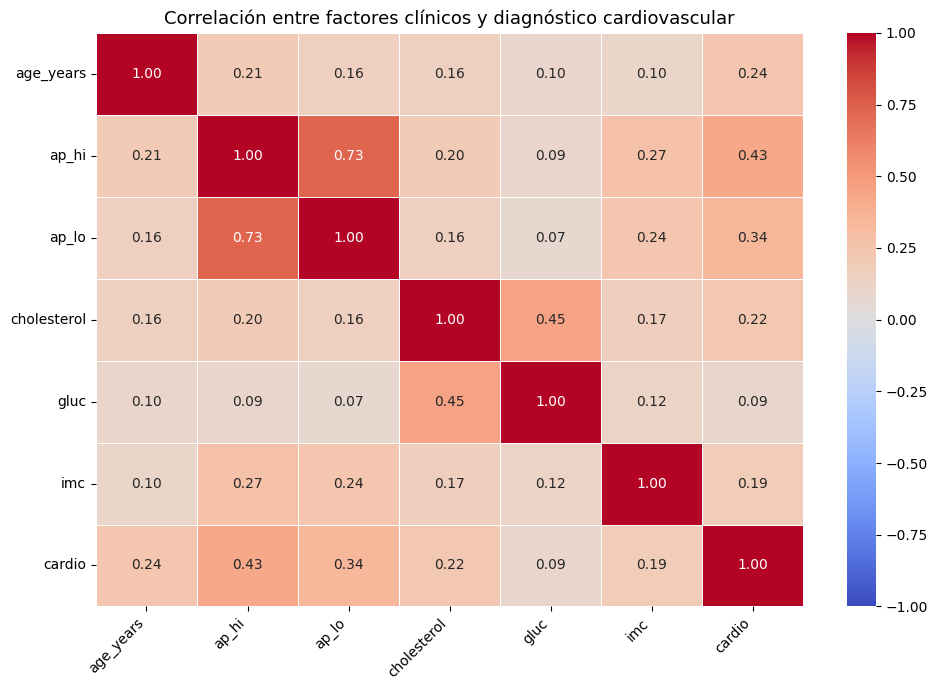

In [88]:
columnas = [
    'age_years',
    'ap_hi',
    'ap_lo',
    'cholesterol',
    'gluc',
    'imc',
    'cardio'
]

correlaciones = data[columnas].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    'Correlación entre factores clínicos y diagnóstico cardiovascular',
    fontsize=13
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### Interpretación del mapa de calor

El análisis muestra que la presión arterial sistólica (0,43) y diastólica (0,34) presentan las mayores correlaciones positivas con el diagnóstico cardiovascular.
La edad (0,24), el colesterol (0,22) y el IMC (0,19) muestran asociaciones más débiles, mientras que la glucosa (0,09) presenta la menor correlación.
Estos resultados sugieren que la presión arterial es un factor relevante en la muestra estudiada, aunque las correlaciones no permiten establecer relaciones causales.

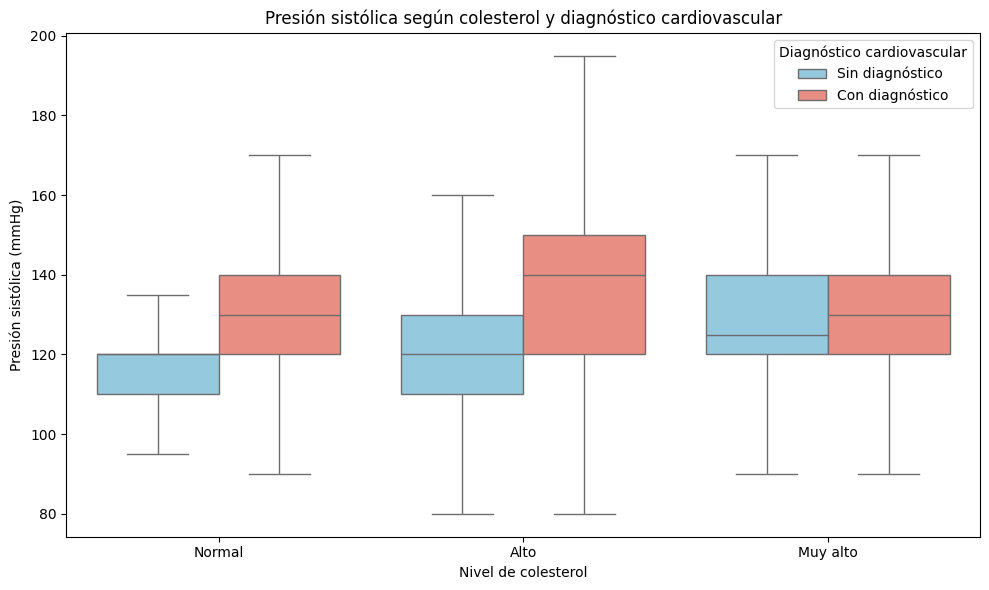

In [89]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x='cholesterol',
    y='ap_hi',
    hue='cardio',
    palette={0: 'skyblue', 1: 'salmon'},
    showfliers=False
)

plt.title(
    'Presión sistólica según colesterol y diagnóstico cardiovascular'
)

plt.xlabel('Nivel de colesterol')
plt.ylabel('Presión sistólica (mmHg)')

plt.xticks(
    [0, 1, 2],
    ['Normal', 'Alto', 'Muy alto']
)

handles, labels = plt.gca().get_legend_handles_labels()

plt.legend(
    handles=handles,
    labels=['Sin diagnóstico', 'Con diagnóstico'],
    title='Diagnóstico cardiovascular'
)

plt.tight_layout()
plt.show()


El gráfico muestra que los pacientes con diagnóstico cardiovascular presentan, en general, valores de presión sistólica más elevados que aquellos sin diagnóstico, especialmente en los grupos con colesterol normal y alto. Esto sugiere una asociación positiva entre la presión arterial sistólica y la presencia de enfermedades cardiovasculares, sin implicar una relación causal.

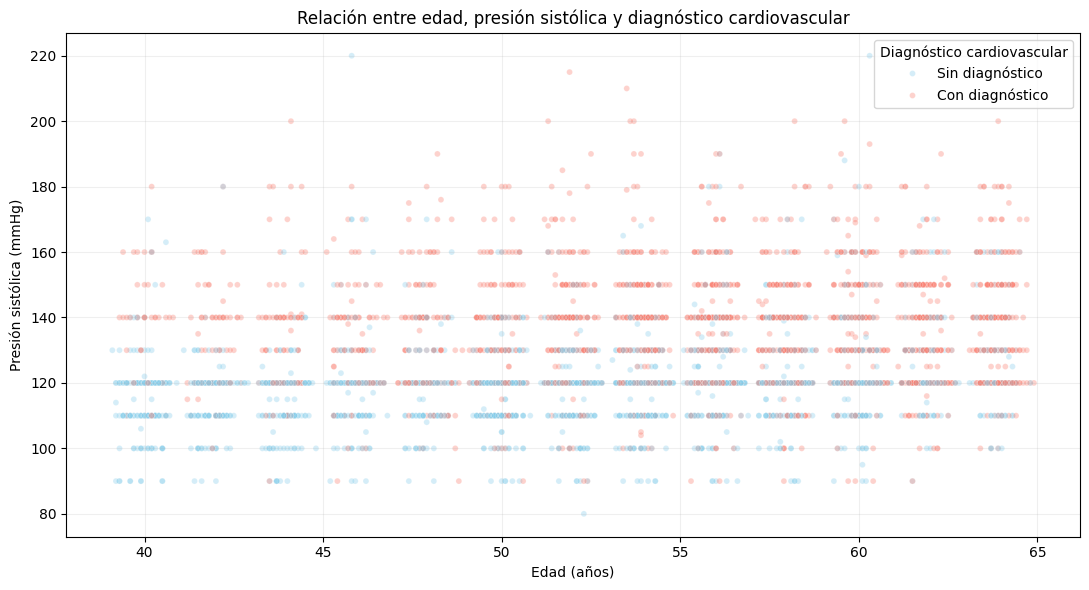

In [90]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=data.sample(n=5000, random_state=42),
    x='age_years',
    y='ap_hi',
    hue='cardio',
    palette={0: 'skyblue', 1: 'salmon'},
    alpha=0.35,
    s=18
)

plt.title(
    'Relación entre edad, presión sistólica y diagnóstico cardiovascular'
)

plt.xlabel('Edad (años)')
plt.ylabel('Presión sistólica (mmHg)')

# Corregir la leyenda
handles, labels = plt.gca().get_legend_handles_labels()

plt.legend(
    handles=handles,
    labels=['Sin diagnóstico', 'Con diagnóstico'],
    title='Diagnóstico cardiovascular'
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


El gráfico muestra una mayor concentración de pacientes con diagnóstico cardiovascular positivo en valores elevados de presión arterial sistólica, especialmente entre 130 y 160 mmHg.
También se observa una presencia importante de diagnósticos positivos en edades mayores, aunque existe superposición entre ambos grupos.
Estos resultados sugieren una asociación entre la presión sistólica, la edad y el diagnóstico cardiovascular, sin establecer relaciones causales

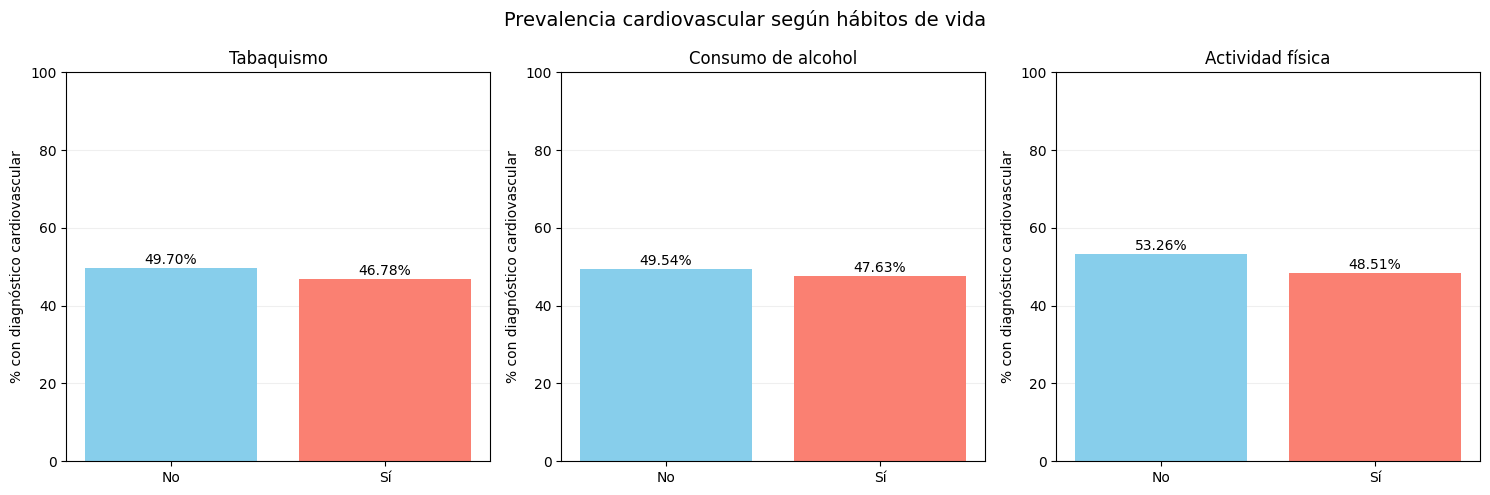

In [91]:
habitos = {
    'Tabaquismo': 'smoke',
    'Consumo de alcohol': 'alco',
    'Actividad física': 'active'
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (nombre, columna) in zip(axes, habitos.items()):

    porcentajes = (
        data.groupby(columna)['cardio'].mean() * 100
    ).reindex([0, 1])

    barras = ax.bar(
        ['No', 'Sí'],
        porcentajes.values,
        color=['skyblue', 'salmon']
    )

    ax.set_title(nombre)
    ax.set_ylabel('% con diagnóstico cardiovascular')
    ax.set_ylim(0, 100)

    for barra in barras:
        altura = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            altura + 1,
            f'{altura:.2f}%',
            ha='center',
            fontsize=10
        )

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle(
    'Prevalencia cardiovascular según hábitos de vida',
    fontsize=14
)

plt.tight_layout()
plt.show()


### Análisis de hábitos de vida y enfermedad cardiovascular
El análisis muestra que las personas físicamente inactivas presentan una mayor prevalencia cardiovascular (53,26%) que las activas (48,51%).
En cuanto al tabaquismo y al consumo de alcohol, se observan diferencias menores entre los grupos, con porcentajes ligeramente inferiores entre quienes declaran estos hábitos.
Estos resultados reflejan asociaciones descriptivas y no permiten establecer relaciones causales.

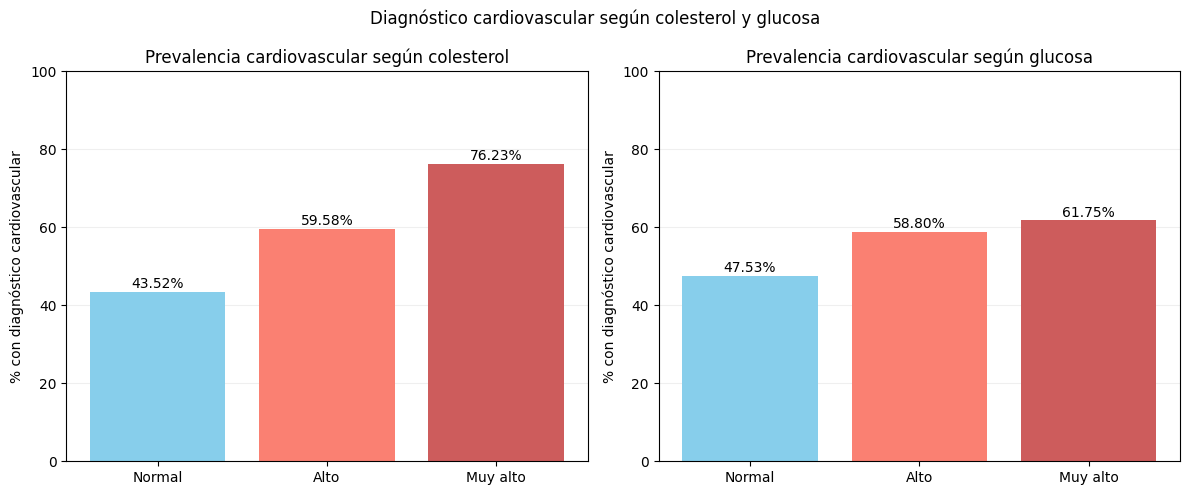

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

variables = {
    'Colesterol': 'cholesterol',
    'Glucosa': 'gluc'
}

for ax, (nombre, columna) in zip(axes, variables.items()):

    porcentajes = (
        data.groupby(columna)['cardio'].mean() * 100
    ).reindex([1, 2, 3])

    barras = ax.bar(
        ['Normal', 'Alto', 'Muy alto'],
        porcentajes.values,
        color=['skyblue', 'salmon', 'indianred']
    )

    ax.set_title(f'Prevalencia cardiovascular según {nombre.lower()}')
    ax.set_ylabel('% con diagnóstico cardiovascular')
    ax.set_ylim(0, 100)

    for barra in barras:
        altura = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            altura + 1,
            f'{altura:.2f}%',
            ha='center'
        )

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle('Diagnóstico cardiovascular según colesterol y glucosa')
plt.tight_layout()
plt.show()

La prevalencia cardiovascular aumenta con los niveles de colesterol, pasando del 43,52% en valores normales al 76,23% en valores muy altos. La glucosa presenta una tendencia similar, aunque menos pronunciada (47,53% a 61,75%).
Estos resultados muestran una asociación positiva entre ambas variables y el diagnóstico cardiovascular, sin establecer causalidad.

# 5. KPI´S

In [93]:

kpi1 = data['cardio'].mean() * 100

kpi2 = (data['ap_hi'] >= 140).mean() * 100

inactivos = data[data['active'] == 0]
kpi3 = inactivos['cardio'].mean() * 100

print("=== INDICADORES CLAVE ===")
print(f"KPI 1 - Prevalencia cardiovascular: {kpi1:.2f}%")
print(f"KPI 2 - Presión sistólica elevada: {kpi2:.2f}%")
print(f"KPI 3 - Prevalencia en inactivos: {kpi3:.2f}%")


=== INDICADORES CLAVE ===
KPI 1 - Prevalencia cardiovascular: 49.44%
KPI 2 - Presión sistólica elevada: 26.85%
KPI 3 - Prevalencia en inactivos: 53.26%


### Interpretación de los indicadores clave (KPIs)

El análisis de los indicadores clave permitió identificar características relevantes de la población estudiada. En primer lugar, se observó una prevalencia cardiovascular del 49,44%, lo que indica que aproximadamente la mitad de los individuos de la muestra presenta un diagnóstico positivo.
En segundo lugar, el 26,85% de los pacientes registró una presión arterial sistólica igual o superior a 140 mmHg, evidenciando una proporción considerable de individuos con valores elevados de presión arterial.
Finalmente, la prevalencia cardiovascular entre las personas físicamente inactivas alcanzó el 53,26%, superando en 3,82 puntos porcentuales la prevalencia general.
Estos resultados sugieren la conveniencia de profundizar el estudio de la relación entre los factores clínicos, los hábitos de vida y la presencia de enfermedades cardiovasculares. Cabe destacar que los indicadores describen exclusivamente la muestra analizada y no deben interpretarse como estimaciones representativas de la población general ni como evidencia de causalidad.

# 6. Conclusiones generales
El análisis de 68.544 registros permitió identificar asociaciones entre factores clínicos, hábitos de vida y la presencia de enfermedades cardiovasculares. La presión arterial sistólica presentó la mayor correlación positiva con el diagnóstico cardiovascular (0,43), seguida de la presión diastólica (0,34). Asimismo, las personas físicamente inactivas registraron una mayor prevalencia cardiovascular (53,26%) que las activas (48,51%).
Los resultados permiten responder a la pregunta inicial, destacando la presión arterial y la actividad física como variables relevantes dentro de la muestra estudiada. No obstante, las asociaciones observadas son descriptivas y no permiten establecer relaciones causales.
Como limitación, se identificó que los registros excluidos durante la limpieza presentaban una mayor prevalencia cardiovascular, por lo que los resultados deben interpretarse considerando el posible sesgo introducido por la depuración.

In [94]:
data.to_csv(
    'cardio_limpio.csv',
    index=False,
    sep=';'
)

print("Dataset limpio exportado correctamente.")
print(f"Total de registros: {len(data)}")
print(f"Total de columnas: {len(data.columns)}")


Dataset limpio exportado correctamente.
Total de registros: 68544
Total de columnas: 16


Se exporta el dataset depurado en formato CSV, conservando los 68.544 registros y las variables transformadas, para su posterior utilización en Power BI.